In [1]:

!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib


In [2]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Create folders
os.makedirs("model", exist_ok=True)
os.makedirs("plots", exist_ok=True)
os.makedirs("dataset", exist_ok=True)

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)
print("Project folders created!")


All libraries imported successfully!
Scikit-learn version: 1.6.1
Project folders created!


In [3]:

# UCI Adult Income dataset URL
dataset_url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/adult/adult.data"
)

# Dataset column names
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

# Download and load dataset
df = pd.read_csv(
    dataset_url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

# Save original downloaded data locally
df.to_csv("dataset/adult_income.csv", index=False)

print("Dataset downloaded successfully!")

print("\nFirst five rows:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)


Dataset downloaded successfully!

First five rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Dataset dimensions:
(32561, 15)


In [4]:

# Display dataset information
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Dataset Description:


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000



Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

Number of rows: 32561
Number of columns: 15


Missing Values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Total Missing Values:
4262


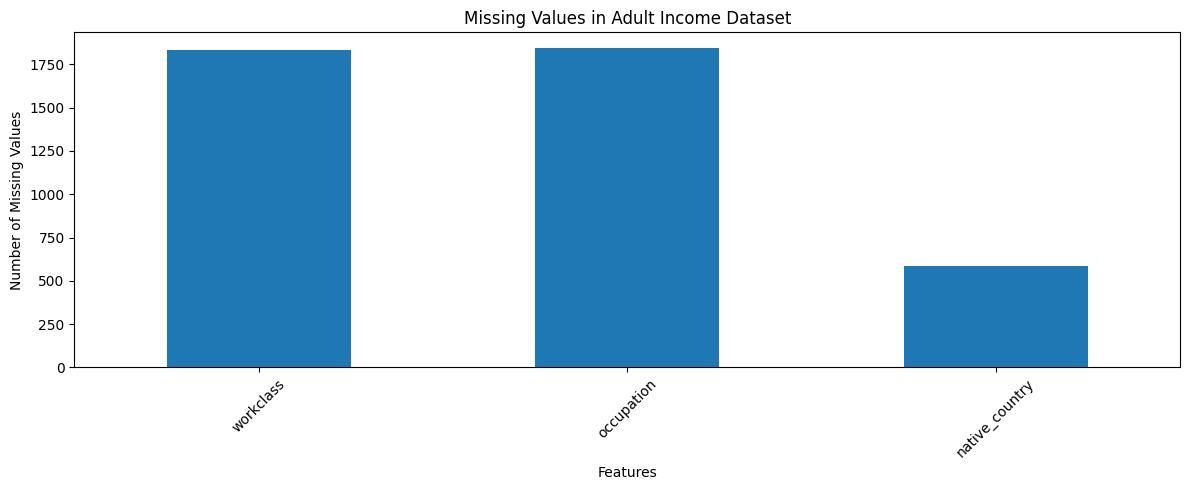

In [5]:

# Count missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

# Visualize missing values
plt.figure(figsize=(12, 5))

missing_values[missing_values > 0].plot(
    kind="bar"
)

plt.title("Missing Values in Adult Income Dataset")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("plots/missing_values.png", dpi=300)
plt.show()


In [6]:

# Count duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Remove records with missing target values
df = df.dropna(subset=["income"]).copy()

print("\nDataset shape after cleaning duplicates:")
print(df.shape)


Number of duplicate records: 24

Dataset shape after cleaning duplicates:
(32537, 15)


Income Class Distribution:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Class Distribution in Percentage:
income
<=50K    75.91
>50K     24.09
Name: proportion, dtype: float64


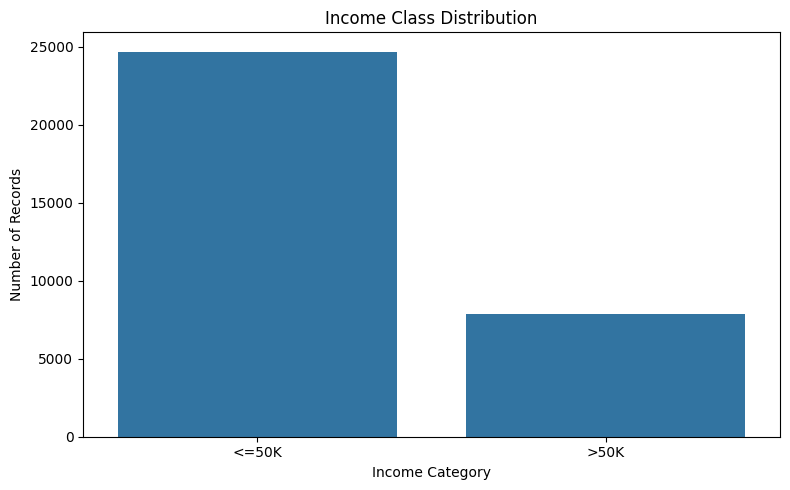

In [7]:

print("Income Class Distribution:")
print(df["income"].value_counts())

print("\nClass Distribution in Percentage:")
print(
    (df["income"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="income"
)

plt.title("Income Class Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.savefig(
    "plots/class_distribution.png",
    dpi=300
)

plt.show()


In [8]:

# Convert target into binary classification labels
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Separate features and target
X = df.drop(columns=["income"])
y = df["income"]

print("Independent Features (X):")
display(X.head())

print("\nDependent Variable (y):")
display(y.head())

print("\nFeature dimensions:", X.shape)
print("Target dimensions:", y.shape)


Independent Features (X):


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba



Dependent Variable (y):


,income
0,0
1,0
2,0
3,0
4,0



Feature dimensions: (32537, 14)
Target dimensions: (32537,)


In [9]:

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:",
      len(numeric_features))

print("Number of Categorical Features:",
      len(categorical_features))


Numerical Features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Number of Numerical Features: 6
Number of Categorical Features: 8


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))


Training Features: (26029, 14)
Testing Features: (6508, 14)

Training Target: (26029,)
Testing Target: (6508,)

Training Class Distribution:
income
0    0.759076
1    0.240924
Name: proportion, dtype: float64

Testing Class Distribution:
income
0    0.759066
1    0.240934
Name: proportion, dtype: float64


In [11]:

def make_preprocessor():

    # Numerical preprocessing
    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    # Categorical preprocessing
    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]
    )

    # Combine both transformers
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer,
                numeric_features
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )

    return preprocessor


print("Preprocessing function created successfully!")


Preprocessing function created successfully!


In [12]:

models = {

    "Logistic Regression":
    LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree":
    DecisionTreeClassifier(
        random_state=42
    ),

    "KNN":
    KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes":
    GaussianNB(),

    "Random Forest":
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

}

print("Five classification models defined!")

for model_name in models:
    print(model_name)


Five classification models defined!
Logistic Regression
Decision Tree
KNN
Naive Bayes
Random Forest


In [13]:

results = []

trained_models = {}

for name, classifier in models.items():

    print("\n" + "=" * 55)
    print("Training:", name)
    print("=" * 55)

    # Create pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", make_preprocessor()),
            ("classifier", classifier)
        ]
    )

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict test labels
    y_pred = pipeline.predict(X_test)

    # Predict probabilities for AUC
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store evaluation results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc
    })

    # Store complete trained pipeline
    trained_models[name] = pipeline

    print("Accuracy:", round(accuracy, 4))
    print("AUC:", round(auc, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("MCC:", round(mcc, 4))

print("\nALL FIVE MODELS TRAINED SUCCESSFULLY!")




Training: Logistic Regression
Accuracy: 0.8569
AUC: 0.9099
Precision: 0.7437
Recall: 0.6199
F1 Score: 0.6762
MCC: 0.5893

Training: Decision Tree
Accuracy: 0.8207
AUC: 0.7539
Precision: 0.6286
Recall: 0.625
F1 Score: 0.6268
MCC: 0.5088

Training: KNN
Accuracy: 0.8379
AUC: 0.8653
Precision: 0.6778
Recall: 0.6237
F1 Score: 0.6496
MCC: 0.5452

Training: Naive Bayes
Accuracy: 0.5361
AUC: 0.7492
Precision: 0.3369
Recall: 0.956
F1 Score: 0.4983
MCC: 0.33

Training: Random Forest
Accuracy: 0.8605
AUC: 0.9083
Precision: 0.7444
Recall: 0.6409
F1 Score: 0.6888
MCC: 0.6023

ALL FIVE MODELS TRAINED SUCCESSFULLY!


In [14]:

results_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON TABLE")

display(
    results_df.round(4)
)

# Save results as CSV
results_df.to_csv(
    "results.csv",
    index=False
)

print("Results saved successfully!")


FINAL MODEL COMPARISON TABLE


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8569,0.9099,0.7437,0.6199,0.6762,0.5893
1,Decision Tree,0.8207,0.7539,0.6286,0.6250,0.6268,0.5088
2,KNN,0.8379,0.8653,0.6778,0.6237,0.6496,0.5452
3,Naive Bayes,0.5361,0.7492,0.3369,0.9560,0.4983,0.3300
4,Random Forest,0.8605,0.9083,0.7444,0.6409,0.6888,0.6023


Results saved successfully!


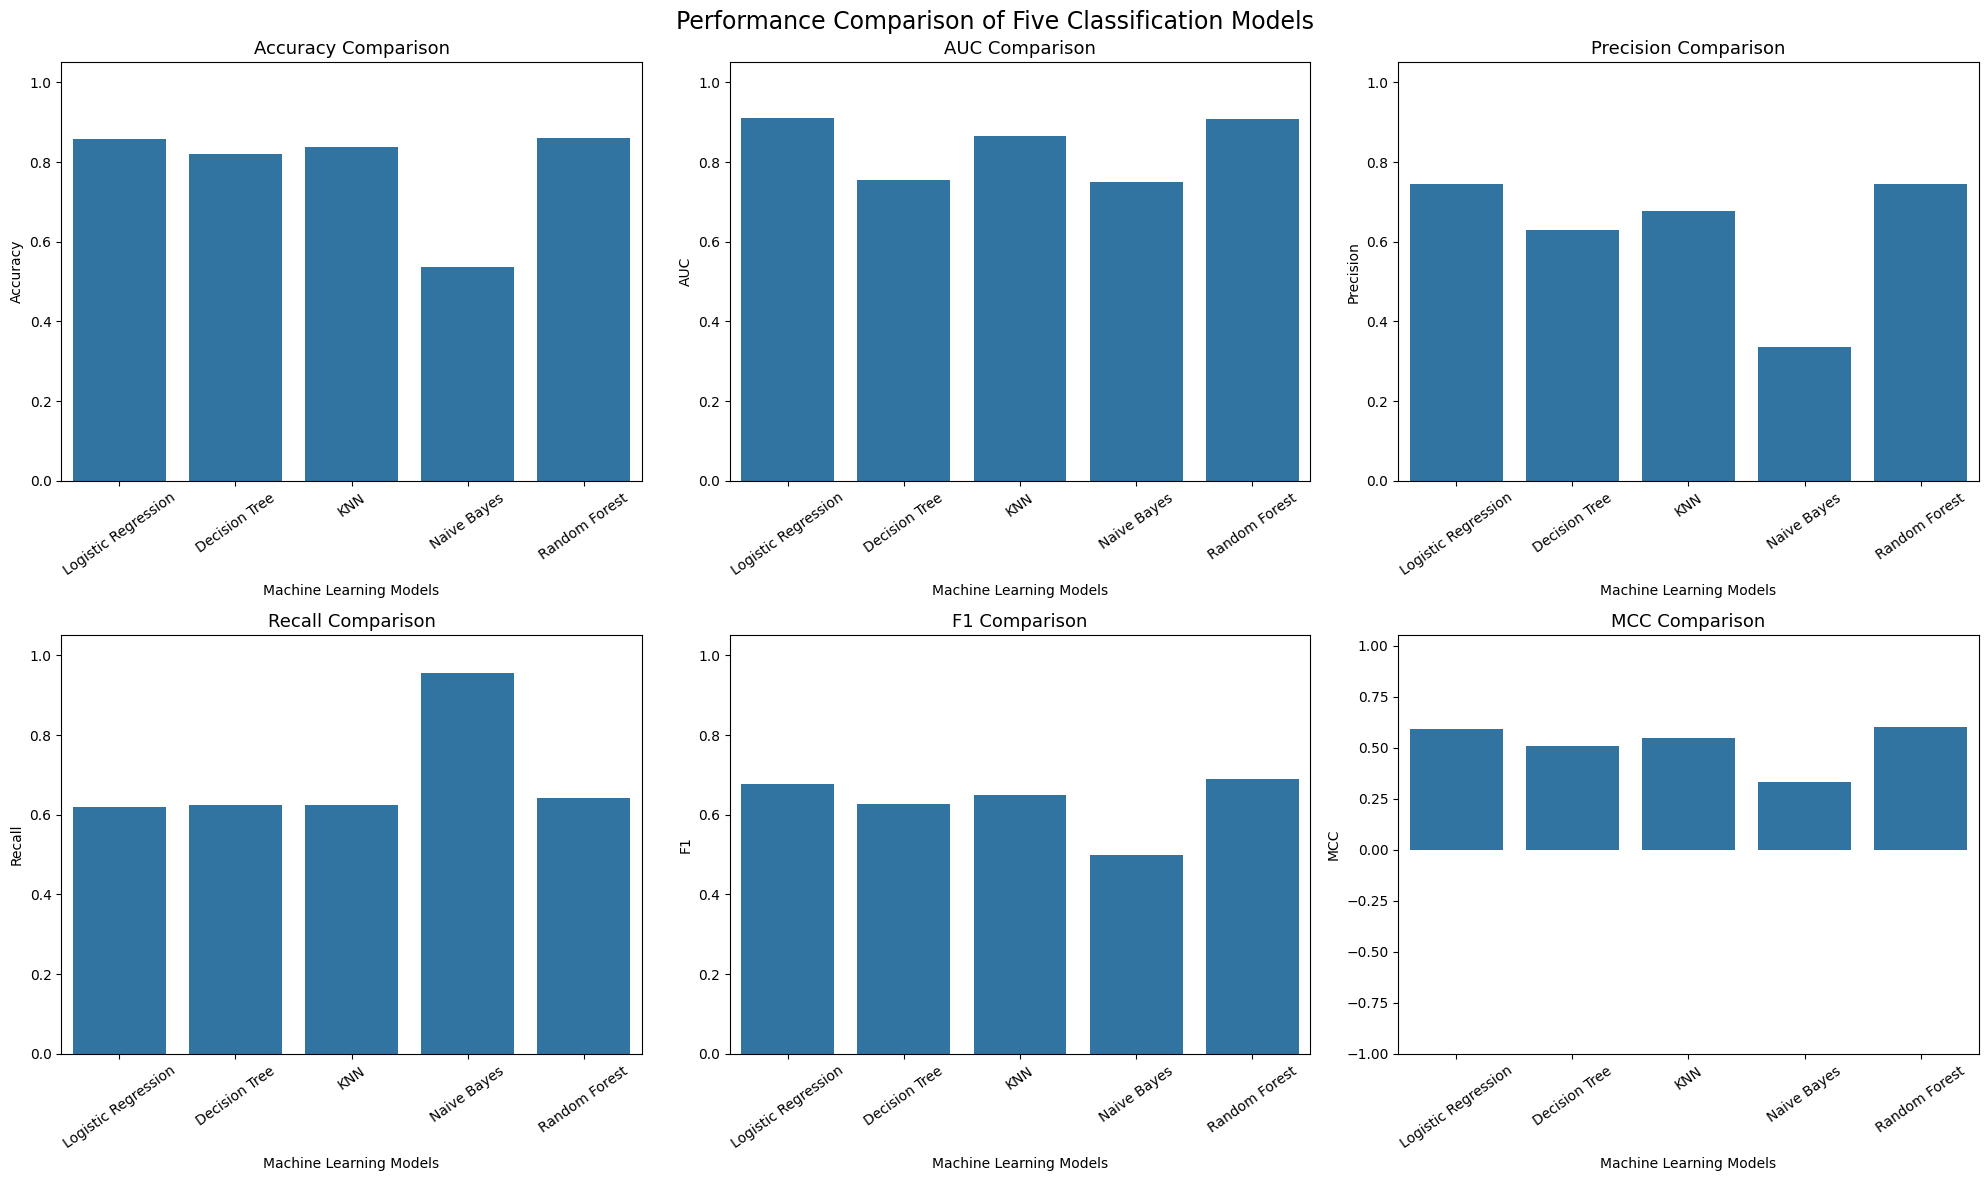

In [16]:

metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 12)
)

for metric, ax in zip(metrics, axes.flatten()):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(
        metric + " Comparison",
        fontsize=13
    )

    ax.set_xlabel("Machine Learning Models")
    ax.set_ylabel(metric)

    ax.tick_params(
        axis="x",
        rotation=35
    )

    ax.set_ylim(-1, 1.05) if metric == "MCC" else ax.set_ylim(0, 1.05)

plt.suptitle(
    "Performance Comparison of Five Classification Models",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "plots/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:

test_data = X_test.copy()

test_data["income"] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test data exported successfully!")

print("Test dataset dimensions:", test_data.shape)

display(test_data.head())


Test data exported successfully!
Test dataset dimensions: (6508, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
20325,27,Private,178709,Masters,14,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,0
23863,51,Local-gov,387250,Bachelors,13,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,50,United-States,1
19987,34,Private,202498,12th,8,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,Dominican-Republic,0
21430,31,Private,133861,Assoc-acdm,12,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,40,United-States,0
9997,34,Private,120461,Some-college,10,Divorced,Adm-clerical,Not-in-family,White,Female,0,0,50,United-States,0


In [18]:

winner = results_df.loc[
    results_df["MCC"].idxmax()
]

print("=" * 50)
print("OVERALL WINNING MODEL")
print("=" * 50)

print("Model:", winner["Model"])
print("Accuracy:", round(winner["Accuracy"], 4))
print("AUC:", round(winner["AUC"], 4))
print("Precision:", round(winner["Precision"], 4))
print("Recall:", round(winner["Recall"], 4))
print("F1 Score:", round(winner["F1"], 4))
print("MCC:", round(winner["MCC"], 4))


OVERALL WINNING MODEL
Model: Random Forest
Accuracy: 0.8605
AUC: 0.9083
Precision: 0.7444
Recall: 0.6409
F1 Score: 0.6888
MCC: 0.6023


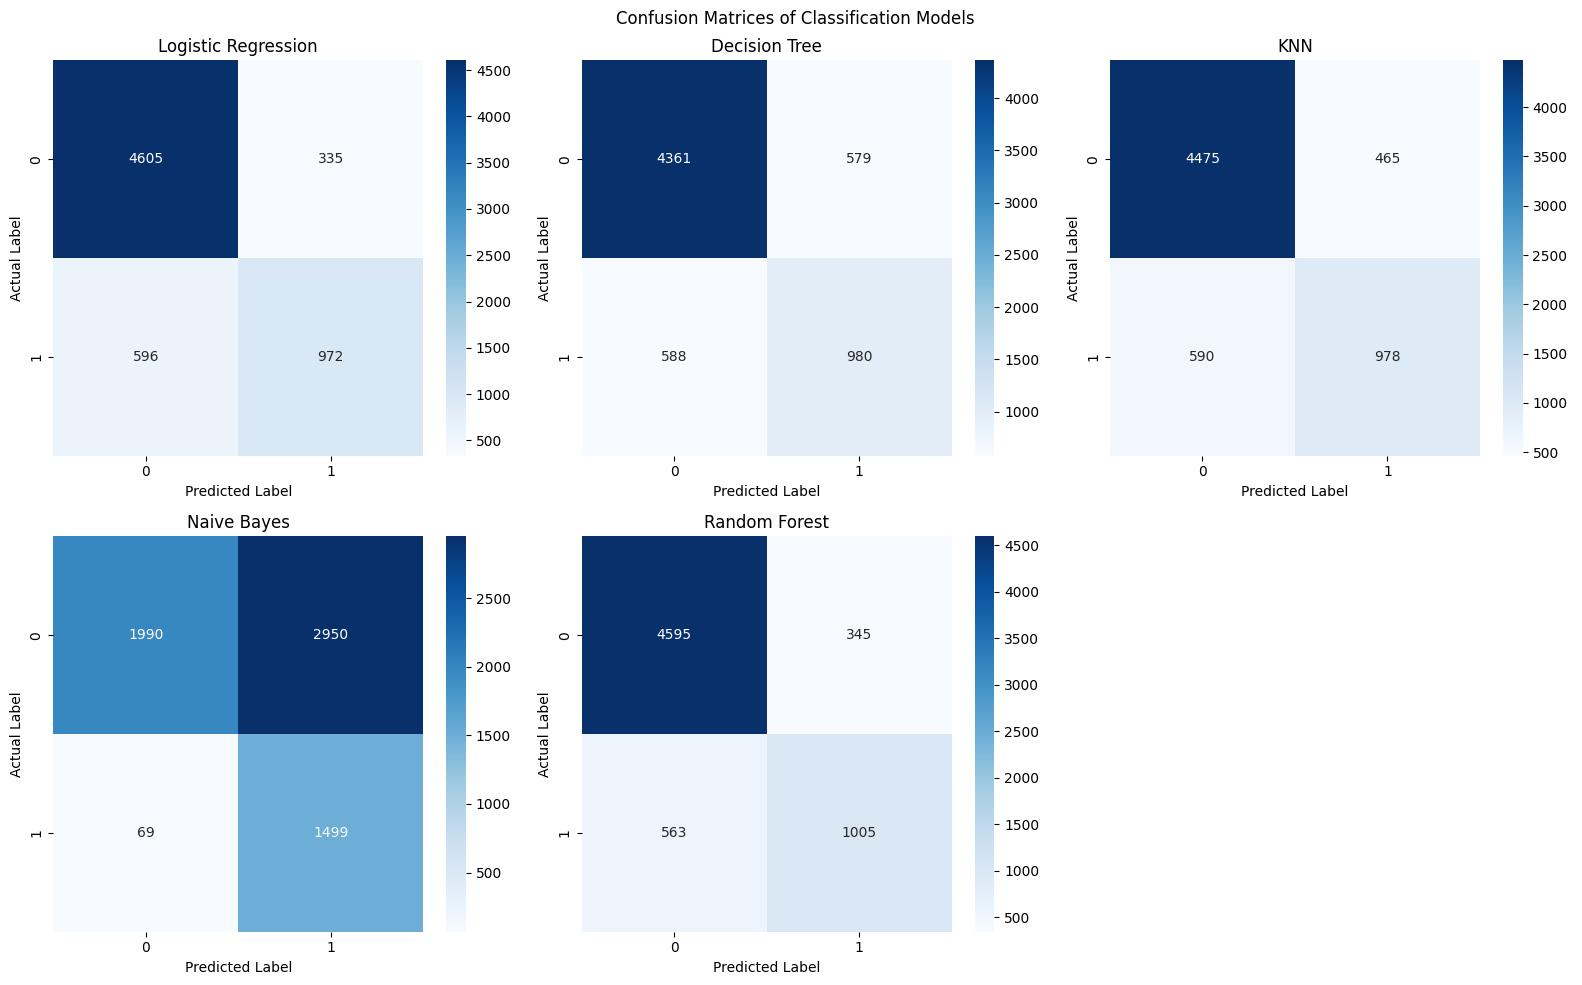

In [19]:

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

for ax, (name, pipeline) in zip(
    axes.flatten(),
    trained_models.items()
):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

# Hide unused sixth subplot
axes.flatten()[-1].axis("off")

plt.suptitle("Confusion Matrices of Classification Models")

plt.tight_layout()

plt.savefig(
    "plots/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

print("PROJECT FILES")
print("=" * 45)

for root, dirs, files in os.walk("."):

    # Ignore unnecessary system folders
    dirs[:] = [
        d for d in dirs
        if d not in [".config", "__pycache__"]
    ]

    for file in files:

        if file.endswith((
            ".csv",
            ".joblib",
            ".png",
            ".py",
            ".md",
            ".txt"
        )):

            print(os.path.join(root, file))


PROJECT FILES
./results.csv
./test_data.csv
./dataset/adult_income.csv
./plots/confusion_matrices.png
./plots/model_comparison.png
./plots/missing_values.png
./plots/class_distribution.png
./sample_data/README.md
./sample_data/california_housing_test.csv
./sample_data/mnist_train_small.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_train.csv


In [21]:

requirements = """pandas
numpy
scikit-learn>=1.2
matplotlib
seaborn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [22]:

# Generate actual results table in Markdown
comparison_table = results_df.round(4).to_markdown(index=False)

readme_content = f"""
# Machine Learning Assignment 2
## Classification Model Comparison

### 1. Problem Statement

The objective of this assignment is to implement and
compare five machine learning classification models
using the Adult Income dataset.

The objective is to predict whether an individual's
income is greater than $50K annually.

### 2. Dataset Description

- Dataset: Adult Income Dataset
- Source: UCI Machine Learning Repository
- URL: https://archive.ics.uci.edu/dataset/2/adult
- Problem Type: Binary Classification
- Input Features: 14
- Target Variable: income
- Final Number of Instances: {len(df)}

The dataset contains numerical and categorical features.
Missing values and class imbalance were examined.

### 3. GitHub Repository Link

Add your GitHub repository URL here after creating it.

### 4. Models Used

The five implemented models are:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Random Forest Classifier

#### Data Preprocessing

- Duplicate records removed.
- Missing numerical values handled using median imputation.
- Missing categorical values handled using mode imputation.
- Categorical features encoded using One-Hot Encoding.
- Numerical features scaled using StandardScaler.
- Train-test split: 80:20.
- Stratified sampling used.
- Random state: 42.

#### Model Configurations

- Logistic Regression: max_iter=2000
- Decision Tree: random_state=42
- KNN: n_neighbors=5
- Gaussian Naive Bayes: default parameters
- Random Forest: n_estimators=100, random_state=42

#### Model Comparison Table

{comparison_table}

#### Graph Representation

See the plots folder for:

- Class distribution
- Missing-value visualization
- Six-metric model comparison
- Confusion matrices

#### Model Performance Observations

Write your interpretation of the actual results for
each of the five models here.

#### Overall Winner

The model with the highest MCC is:

**{winner['Model']}**

MCC: {winner['MCC']:.4f}

The overall winner is selected based on MCC, while
considering the other evaluation metrics.

### 5. Execution Instructions

Install dependencies:

    pip install -r requirements.txt

Open the notebook:

    jupyter notebook ML_Assignment_2_Classification.ipynb

Execute all notebook cells in order.

The project generates:
- results.csv
- test_data.csv
- Five trained model files
- Performance graphs
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README.md generated successfully!")


README.md generated successfully!


In [23]:

import os
import zipfile
from google.colab import files

zip_name = "ML_Assignment_2_Project.zip"

# Files and folders to include
include_items = [
    "dataset",
    "model",
    "plots",
    "test_data.csv",
    "results.csv",
    "requirements.txt"
]

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for item in include_items:

        if os.path.isfile(item):
            zipf.write(item)

        elif os.path.isdir(item):
            for root, dirs, filenames in os.walk(item):
                for filename in filenames:
                    path = os.path.join(root, filename)
                    zipf.write(path)

print("Project ZIP created successfully!")

files.download(zip_name)


Project ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

import os
import zipfile
from pathlib import Path
from google.colab import files

# Colab working directory
base = Path("/content")

# Find all saved model files
model_extensions = [".joblib", ".pkl", ".sav"]

model_files = [
    p for p in base.rglob("*")
    if p.is_file() and p.suffix.lower() in model_extensions
    and "sample_data" not in p.parts
]

print("TRAINED MODEL FILES FOUND:")
for p in model_files:
    print(p)

# Check whether any models were actually saved
if not model_files:
    print("\nWARNING: No saved model files found.")
    print("We will need to locate or save your trained models.")

# Create ZIP containing project files
zip_path = base / "ML_Assignment_2_Complete.zip"

exclude_dirs = {
    "sample_data",
    "__pycache__",
    ".config"
}

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, filenames in os.walk(base):

        dirs[:] = [
            d for d in dirs
            if d not in exclude_dirs
        ]

        for filename in filenames:
            filepath = Path(root) / filename

            if filepath == zip_path:
                continue

            # Skip temporary notebook checkpoint files
            if ".ipynb_checkpoints" in filepath.parts:
                continue

            # Keep files relative to /content
            arcname = filepath.relative_to(base)

            zf.write(filepath, arcname)

print("\nComplete ZIP created:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

files.download(str(zip_path))


TRAINED MODEL FILES FOUND:

We will need to locate or save your trained models.

Complete ZIP created: /content/ML_Assignment_2_Complete.zip
ZIP size: 2.33 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

import os

print("========== ALL PROJECT FILES ==========")

for root, dirs, files_list in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        "sample_data", "__pycache__"
    ]]

    for filename in files_list:
        path = os.path.join(root, filename)
        print(path)

print("\n========== CHECKING IMPORTANT FILES ==========")

extensions = [".joblib", ".pkl", ".sav"]

for root, dirs, files_list in os.walk("/content"):
    for filename in files_list:
        if filename.endswith(tuple(extensions)):
            print("MODEL FOUND:", os.path.join(root, filename))

print("\n========== CHECKING FOLDERS ==========")

for folder in ["dataset", "model", "plots"]:
    path = "/content/" + folder
    print(folder, ":", "EXISTS" if os.path.exists(path) else "MISSING")


========== ALL PROJECT FILES ==========
/content/ML_Assignment_2_Project.zip
/content/results.csv
/content/requirements.txt
/content/ML_Assignment_2_Complete.zip
/content/test_data.csv
/content/README.md
/content/.config/.last_update_check.json
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/config_sentinel
/content/.config/.last_opt_in_prompt.yaml
/content/.config/default_configs.db
/content/.config/.last_survey_prompt.yaml
/content/.config/gce
/content/.config/active_config
/content/.config/configurations/config_default
/content/.config/logs/2026.10.21/13.27.58.650478.log
/content/.config/logs/2026.10.21/13.28.04.564766.log
/content/.config/logs/2026.10.21/13.27.51.774504.log
/content/.config/logs/2026.10.21/13.27.57.480371.log
/content/.config/logs/2026.10.21/13.28.05.116687.log
/content/.config/logs/2026.10.21/13.27.28.750982.log
/content/dataset/adult_income.csv
/content/plots/confusion_matrices.png
/content/plots/model_comparison.p

In [26]:

# Check whether your trained models are still available in memory

from sklearn.base import BaseEstimator

print("========== AVAILABLE TRAINED MODELS ==========")

found_models = {}

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, BaseEstimator):
            print(f"Variable: {name}")
            print(f"Type: {type(obj).__name__}")
            found_models[name] = obj
    except Exception:
        pass

print("\nTotal model/pipeline objects found:", len(found_models))

print("\n========== MODEL FOLDER CONTENTS ==========")

import os

print(os.listdir("/content/model"))


========== AVAILABLE TRAINED MODELS ==========
Variable: classifier
Type: RandomForestClassifier
Variable: pipeline
Type: Pipeline

Total model/pipeline objects found: 2

========== MODEL FOLDER CONTENTS ==========
[]


In [27]:

# Check all important model-related variables

print("MODEL VARIABLES")

for name in [
    "logistic_model",
    "decision_tree_model",
    "knn_model",
    "nb_model",
    "rf_model",
    "classifier",
    "pipeline"
]:
    if name in globals():
        print(name, "FOUND")
    else:
        print(name, "NOT FOUND")

print("\nRESULTS DATAFRAME")
print(results_df)


MODEL VARIABLES
logistic_model NOT FOUND
decision_tree_model NOT FOUND
knn_model NOT FOUND
nb_model NOT FOUND
rf_model NOT FOUND
classifier FOUND
pipeline FOUND

RESULTS DATAFRAME
                 Model  Accuracy       AUC  Precision    Recall        F1  \
0  Logistic Regression  0.856945  0.909903   0.743688  0.619898  0.676174   
1        Decision Tree  0.820682  0.753897   0.628608  0.625000  0.626799   
2                  KNN  0.837892  0.865253   0.677755  0.623724  0.649618   
3          Naive Bayes  0.536109  0.749245   0.336930  0.955995  0.498255   
4        Random Forest  0.860479  0.908302   0.744444  0.640944  0.688828   

        MCC  
0  0.589333  
1  0.508794  
2  0.545202  
3  0.329962  
4  0.602345  


In [28]:

print("PIPELINE STEPS:")
print(pipeline.named_steps)

print("\nCLASSIFIER:")
print(classifier)

print("\nPIPELINE FINAL ESTIMATOR:")
print(type(pipeline.steps[-1][1]))


PIPELINE STEPS:
{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'fnlwgt', 'education_num',
                                  'capital_gain', 'capital_loss',
                                  'hours_per_week']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['workclass', 'education', 'marital_status',
  

In [29]:
for name in [
    "X_train", "X_test", "y_train", "y_test",
    "X", "y", "df", "preprocessor",
    "preprocessing", "results_df"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "FOUND",
            "| Type:", type(obj).__name__,
            "| Shape:", getattr(obj, "shape", "N/A")
        )
    else:
        print(name, "NOT FOUND")


X_train FOUND | Type: DataFrame | Shape: (26029, 14)
X_test FOUND | Type: DataFrame | Shape: (6508, 14)
y_train FOUND | Type: Series | Shape: (26029,)
y_test FOUND | Type: Series | Shape: (6508,)
X FOUND | Type: DataFrame | Shape: (32537, 14)
y FOUND | Type: Series | Shape: (32537,)
df FOUND | Type: DataFrame | Shape: (32537, 15)
preprocessor NOT FOUND
preprocessing NOT FOUND
results_df FOUND | Type: DataFrame | Shape: (5, 7)


In [30]:

import os
import joblib
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

from sklearn.utils.validation import check_is_fitted

# Create model directory
os.makedirs("/content/model", exist_ok=True)

# Define the four classifiers to recreate
classifiers = {
    "logistic_regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "decision_tree": DecisionTreeClassifier(
        random_state=42
    ),
    "knn": KNeighborsClassifier(
        n_neighbors=5
    ),
    "naive_bayes": GaussianNB()
}

# Verify that the existing Random Forest pipeline is fitted
check_is_fitted(pipeline)

# Store the existing fitted Random Forest pipeline
trained_models = {
    "random_forest": pipeline
}

# Train the other four models using the same preprocessing
for name, estimator in classifiers.items():

    print(f"Training {name}...")

    model_pipeline = clone(pipeline)

    # Replace only the classifier; retain the original preprocessor
    model_pipeline.set_params(classifier=estimator)

    # Fit on the original training data
    model_pipeline.fit(X_train, y_train)

    trained_models[name] = model_pipeline

    print(f"{name} trained successfully!")

# Evaluate and save all five models
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    results.append(metrics)

    # Save the complete fitted pipeline
    filepath = f"/content/model/{name}.joblib"
    joblib.dump(model, filepath)

    print(f"Saved: {filepath}")

# Create a separate results file for these fitted pipelines
new_results_df = pd.DataFrame(results)

new_results_df.to_csv(
    "/content/model/recreated_model_results.csv",
    index=False
)

print("\nALL FIVE MODELS SAVED SUCCESSFULLY!")
print("\nNEW MODEL RESULTS:")
display(new_results_df)

print("\nSAVED MODEL FILES:")
print(os.listdir("/content/model"))


Training logistic_regression...
logistic_regression trained successfully!
Training decision_tree...
decision_tree trained successfully!
Training knn...
knn trained successfully!
Training naive_bayes...
naive_bayes trained successfully!
Saved: /content/model/random_forest.joblib
Saved: /content/model/logistic_regression.joblib
Saved: /content/model/decision_tree.joblib
Saved: /content/model/knn.joblib
Saved: /content/model/naive_bayes.joblib

ALL FIVE MODELS SAVED SUCCESSFULLY!

NEW MODEL RESULTS:


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,random_forest,0.860479,0.908302,0.744444,0.640944,0.688828,0.602345
1,logistic_regression,0.856945,0.909903,0.743688,0.619898,0.676174,0.589333
2,decision_tree,0.820682,0.753897,0.628608,0.625000,0.626799,0.508794
3,knn,0.837892,0.865253,0.677755,0.623724,0.649618,0.545202
4,naive_bayes,0.536109,0.749245,0.336930,0.955995,0.498255,0.329962



SAVED MODEL FILES:
['recreated_model_results.csv', 'knn.joblib', 'decision_tree.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'random_forest.joblib']


In [31]:
import os

for file in sorted(os.listdir("/content/model")):
    path = os.path.join("/content/model", file)
    print(file, "—", round(os.path.getsize(path) / 1024, 2), "KB")

decision_tree.joblib — 605.39 KB
knn.joblib — 21562.4 KB
logistic_regression.joblib — 8.01 KB
naive_bayes.joblib — 10.36 KB
random_forest.joblib — 71582.5 KB
recreated_model_results.csv — 0.65 KB


In [32]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/ML_Assignment_2_Models",
    "zip",
    "/content/model"
)

files.download("/content/ML_Assignment_2_Models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

import os
import shutil
from google.colab import files

# Create final project directory
project_dir = "/content/ML_Assignment_2_Final"
os.makedirs(project_dir, exist_ok=True)

# Copy important project files
files_to_copy = [
    "README.md",
    "requirements.txt",
    "results.csv",
    "test_data.csv"
]

for filename in files_to_copy:
    source = f"/content/{filename}"
    if os.path.isfile(source):
        shutil.copy2(source, project_dir)
        print("Added:", filename)

# Copy project folders
folders_to_copy = ["dataset", "model", "plots"]

for folder in folders_to_copy:
    source = f"/content/{folder}"
    destination = os.path.join(project_dir, folder)

    if os.path.isdir(source):
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print("Added folder:", folder)

# Find and include ALL notebooks inside /content
notebook_dir = os.path.join(project_dir, "notebooks")
os.makedirs(notebook_dir, exist_ok=True)

notebook_count = 0

for root, dirs, filenames in os.walk("/content"):
    # Avoid copying the output folder into itself
    dirs[:] = [
        d for d in dirs
        if os.path.abspath(os.path.join(root, d))
        != os.path.abspath(project_dir)
    ]

    for filename in filenames:
        if filename.endswith(".ipynb"):
            source = os.path.join(root, filename)

            # Preserve relative folder structure
            relative_path = os.path.relpath(source, "/content")
            destination = os.path.join(notebook_dir, relative_path)

            os.makedirs(os.path.dirname(destination), exist_ok=True)
            shutil.copy2(source, destination)

            notebook_count += 1
            print("Added notebook:", relative_path)

# Create one ZIP file
zip_base = "/content/ML_Assignment_2_Final"

if os.path.exists(zip_base + ".zip"):
    os.remove(zip_base + ".zip")

shutil.make_archive(zip_base, "zip", project_dir)

print("\n================================")
print("FINAL PROJECT ZIP CREATED!")
print("Notebooks included:", notebook_count)
print("================================")

# Download everything together
files.download(zip_base + ".zip")


Added: README.md
Added: requirements.txt
Added: results.csv
Added: test_data.csv
Added folder: dataset
Added folder: model
Added folder: plots

FINAL PROJECT ZIP CREATED!
Notebooks included: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>